First, I download the data, check for missing values and compute each stock's annualized return and volatility, then compare their performance with the index 

In [2]:
import seaborn as sns
import yfinance as yf 
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt


data = yf.download(['TTE.PA', 'MC.PA', 'RMS.PA', 'OR.PA', 'SAN.PA','AIR.PA', 'BNP.PA', 'SU.PA', 'AI.PA', 'CAP.PA', '^FCHI'], start ='2021-01-01', end = '2026-01-01', auto_adjust = False)
price = data['Adj Close'] 
missing_values = price.isnull().sum()

if missing_values.sum() != 0:
    print(f'There are {missing_values.sum()} missing values, {missing_values}')
else:
    print('he data is ready to use')

returns = price.pct_change()

annualized_r = returns.mean()*252
annualized_vol = returns.std()*np.sqrt(252)

summary = pd.DataFrame ({'annualized returns in % ':annualized_r *100 , 'Annualized volatility in %':annualized_vol*100}).round(2).sort_values('annualized returns in % ',ascending = False)
summary                     

[*********************100%***********************]  11 of 11 completed

he data is ready to use


,annualized returns in %,Annualized volatility in %
Ticker,,
BNP.PA,23.23,28.13
RMS.PA,21.79,27.53
AIR.PA,21.04,28.63
SU.PA,18.71,27.89
TTE.PA,18.16,24.10
MC.PA,10.46,29.12
AI.PA,10.41,18.45
^FCHI,8.72,16.08
CAP.PA,7.55,27.69


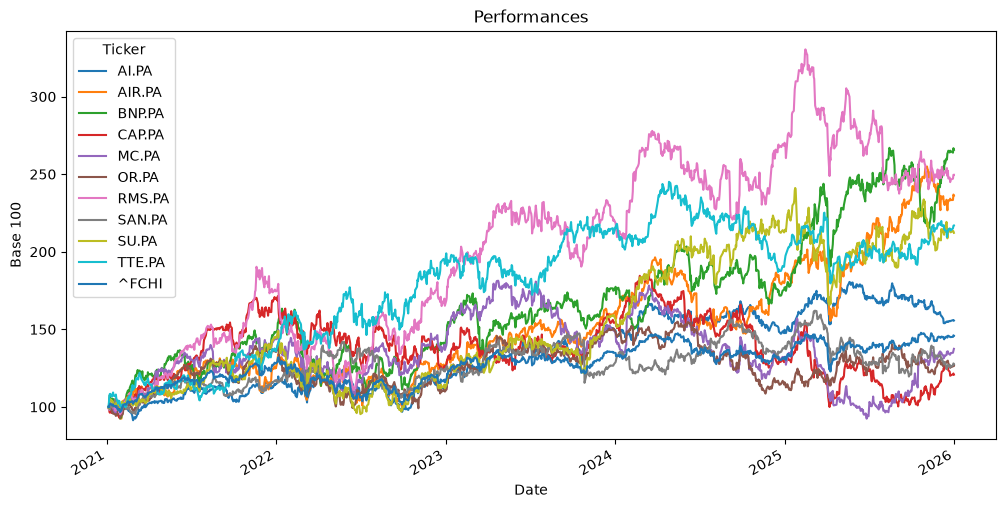

In [16]:
normalized_price = price/price.iloc[0] * 100 

normalized_price.plot(figsize=(12, 6), title="Performances")
plt.ylabel("Base 100")
plt.show()

The figures and the graph show that  6 stocks performed better than the CAC 40. Some of them, such as BNP has a return close to 3 times index's return! Even the weakest performers of this portfolio, like Sanofi, has a return close to the CAC 40

We can also clearly see the benefits of diversification, while every stock has a volatility close to 25%, CAC 40 is only at 16%


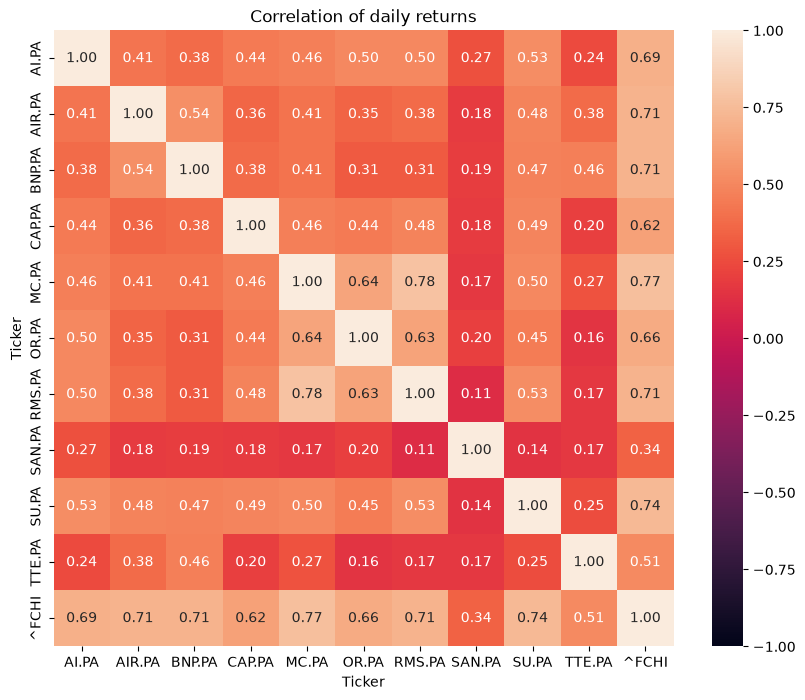

In [3]:

returns.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(returns.corr(), annot=True, fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation of daily returns")
plt.show()

The goal of this step is to find which stocks are the most and the least correlated

The most correlated pair is Hermès and LVMH, which is not a big surprise since they are the only two companies from the same sector in this analysis

The heatmap clearly shows that two stocks are less correlated with the others: Sanofi and TotalEnergies. Sanofi operates in healthcare, a very defensive sector with relatively little fluctuation, while TotalEnergies is driven by oil prices and is less exposed to the French economic situation

These two stocks could therefore be very useful to diversify our portfolio

Now, we can focus on the relation between return and risk for our 10 stocks and the CAC 40 

To analyse it, we can use the Sharpe ratio and a graph with volatility on the x axis and returns on the y axis  

To simplify, I'm taking a risk free rate of 2% in the Sharpe ratio formula 

In [9]:
sharpe_ratio = (annualized_r-0.02)/annualized_vol
sharpe_ratio

Ticker
AI.PA     0.455756
AIR.PA    0.664876
BNP.PA    0.754643
CAP.PA    0.200563
MC.PA     0.290607
OR.PA     0.229377
RMS.PA    0.718868
SAN.PA    0.239538
SU.PA     0.599039
TTE.PA    0.670517
^FCHI     0.417955
dtype: float64

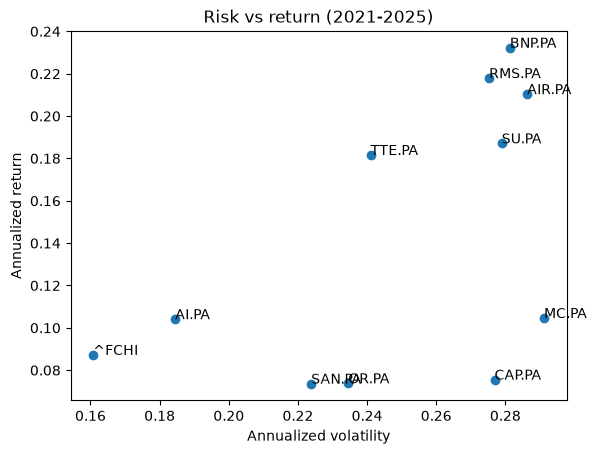

In [33]:
plt.scatter(annualized_vol, annualized_r)
for ticker in annualized_r.index:
    plt.annotate(ticker,(annualized_vol[ticker], annualized_r[ticker]))
plt.xlabel("Annualized volatility")
plt.ylabel("Annualized return")
plt.title("Risk vs return (2021-2025)")
plt.show()

6 stocks have a higher Sharpe ratio than the index, and 7 have a better return/volatility ratio. Our equal-weight portfolio may have the potential to outperform the CAC 40! 

It's time now to create our equal-weighted portfolio and analyze its performance

In [28]:
stocks = returns.drop(columns = '^FCHI')
portfolio_returns = stocks.mean(axis=1)
annualized_portfolio_r = (portfolio_returns.mean()*252).round(4)
annualized_portfolio_vol = (portfolio_returns.std()*np.sqrt(252)).round(4)
sharpe_portfolio = ((annualized_portfolio_r-0.02)/annualized_portfolio_vol).round(4)


plt.ylabel("Base 100")
plt.show()

print(f"Portfolio return: {annualized_portfolio_r:.2%}\nPortfolio volatility: {annualized_portfolio_vol:.2%}\nSharpe Ratio = {sharpe_portfolio}\n")

Portfolio return: 14.61%
Portfolio volatility: 17.16%
Sharpe Ratio = 0.7348



Great ! With our equal-weighteid portfolio, we performed a higher annualized return than the CAC 40 (8.7% for the index VS 14.61% for our portfolio). And the annualized volatility is similar to the index (only 1% higher). The Sharpe ratio of the portfolio is also clearly better than CAC 40's Sharpe ratio (0.7340 VS 0.4179) 

Now let's analyse it with a graph and conclude. 

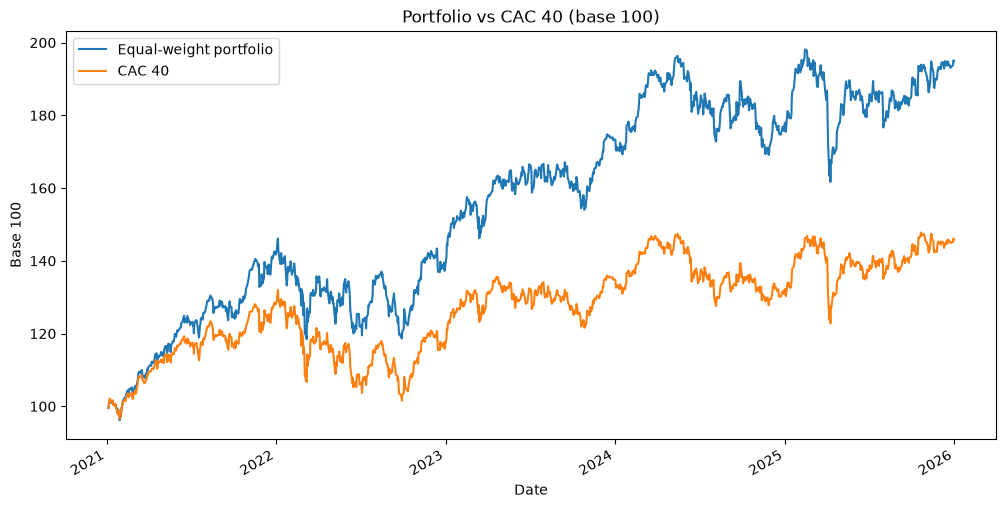

In [32]:
comparison = pd.DataFrame({'Equal-weight portfolio': (1 + portfolio_returns).cumprod() * 100,'CAC 40': (1 + returns['^FCHI']).cumprod() * 100,})

comparison.plot(figsize=(12, 6), title="Portfolio vs CAC 40 (base 100)")
plt.ylabel("Base 100")
plt.show()

Over the period, the portfolio clearly outperforms the index! After 5 years, the portfolio has almost doubled, while the CAC 40 only rose by about 50%.

But why does this gap exist?

Most of the gain comes from a few stocks, mainly BNP Paribas, Hermès, TotalEnergies and Airbus. Diversification also helped: most stocks move around 25% a year, but the portfolio is close to the index at 17%. Mixing 10 stocks from different sectors already removes a big part of the risk of holding a single stock.

A few things to keep in mind:

- The stock prices include dividends, but the CAC 40 index does not. That alone explains about 3% a year of the gap.

- I picked the stocks from today’s CAC 40, so they are all companies that did well enough to stay in it (survivorship bias).

- The portfolio is rebalanced every day for free, which you can’t do in real life.

- Five years is short, it would be interesting to analyse it on a longer timeline (around 30 years) 